## Постановка задачи
- **Объект наблюдения:** один заказ.
- **Целевая переменная:** `actual_delivery_time_minutes` — минуты от размещения заказа до завершения доставки.
- **Тип задачи:** регрессия.
- **Момент прогноза:** размещение заказа. Использовать можно только то, что известно в этот момент.
- **Метрики:** MAE, RMSE
- **Бенчмарк:** в данных есть собственный прогноз платформы `estimated_delivery_time_minutes`. Его берём как бенчмарк.


## Импорты и загрузка

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [9]:
FILE_PATH="../food_delivery_orders_dataset.csv" # пока локально, потом мб переделаю
SEED=67 #сикс севен
TARGET = "actual_delivery_time_minutes"
BENCHMARK  = "estimated_delivery_time_minutes"
np.random.seed(SEED)

In [3]:
df = pd.read_csv(FILE_PATH)
df.head(10)

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9
5,ORD_000006,CUS_00580,RES_0019,DRV_0112,2025-10-23 14:27:00,2025-10-23,14,Thursday,0,City_B,...,Medium,34,5.0,12,32,39.0,1.0,Completed,NaN,4.0
6,ORD_000007,CUS_00021,RES_0002,DRV_0109,2025-10-29 19:20:00,2025-10-29,19,Wednesday,0,City_D,...,Medium,43,4.8,11,27,31.0,0.0,Completed,NaN,4.5
7,ORD_000008,CUS_00003,RES_0044,DRV_0066,2025-10-26 07:22:00,2025-10-26,7,Sunday,1,City_D,...,Low,53,4.0,12,20,22.0,0.0,Completed,NaN,4.8
8,ORD_000009,CUS_00002,RES_0003,DRV_0155,2025-10-24 14:28:00,2025-10-24,14,Friday,0,City_C,...,High,46,4.5,11,37,40.0,0.0,Completed,NaN,5.0
9,ORD_000010,CUS_00009,RES_0009,DRV_0126,2025-10-14 20:32:00,2025-10-14,20,Tuesday,0,City_B,...,Medium,47,4.0,14,25,22.0,0.0,Completed,NaN,4.8


In [4]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "% пропусков": (df.isna().mean() * 100).round(2),
    "уникальных": df.nunique(),
})
info

,dtype,пропусков,% пропусков,уникальных
order_id,str,0,0.00,50000
customer_id,str,0,0.00,4979
restaurant_id,str,0,0.00,250
driver_id,str,0,0.00,200
order_timestamp,str,0,0.00,25459
order_date,str,0,0.00,30
order_hour,int64,0,0.00,24
day_of_week,str,0,0.00,7
is_weekend,int64,0,0.00,2
city,str,0,0.00,4


**Вывод**: заказов-дубликатов нет, есть пропуски в столбцах, коррелирующие с отменой заказа. Проверим

In [7]:
print(pd.crosstab(df["order_status"], df["actual_delivery_time_minutes"].isna()))
print()
print(df["cancellation_reason"].value_counts())

actual_delivery_time_minutes  False  True 
order_status                              
Cancelled                         0    868
Completed                     49132      0

cancellation_reason
Driver Unassigned         386
Restaurant Unavailable    160
Customer Cancelled        154
Changed Mind              153
Long Prep Delay            15
Name: count, dtype: int64


Да, те самые 868 отмененных заказов. Уберём их из данных.

In [8]:
df = df[df["order_status"] == "Completed"].reset_index(drop=True)

## Признаки

Некоторые признаки надо убрать чисто из здравого смысла, а именно из-за того, что они вытекают из таргета, а не наоборот. Это `late_delivery`, `tip_amount` и `customer_rating`. `order_status` и `cancellation_reason` не имеют смысла после фильтрации, так что тоже идут отдыхать, дабы не занимать место. Также есть признаки, которые явно связаны, причём скорее всего линейно - это `tax_amount`, `service_fee`, `order_total` для `subtotal`. Они идут в LEAK_COLS

In [15]:
# самые основные признаки, по которым уже можно сделать какую-то модель, по ним проверим kfold
CORE_NUM_FEATURES = ["distance_km", "restaurant_preparation_time_minutes",
            "delivery_partner_experience_months", "delivery_partner_rating"]
CORE_CAT_FEATURES = ["traffic_level", "weather"] 

TIME_FEATURES = ["order_timestamp", "order_date"]
ID_COLS = ["order_id", "customer_id", "restaurant_id", "driver_id"]
LEAK_COLS  = ["late_delivery", "customer_rating", "tip_amount", "order_status", "cancellation_reason", "tax_amount", "service_fee", "order_total"]

OTHER = [c for c in df.columns
         if c not in ID_COLS + TIME_FEATURES + LEAK_COLS + [BENCHMARK, TARGET] + CORE_NUM_FEATURES + CORE_CAT_FEATURES
         ] 

## Распределения признаков

таргет

count    49132.00
mean        35.15
std         14.70
min         10.00
1%          12.00
5%          17.00
25%         25.00
50%         33.00
75%         42.00
95%         63.00
99%         85.00
max        172.00
Name: actual_delivery_time_minutes, dtype: float64


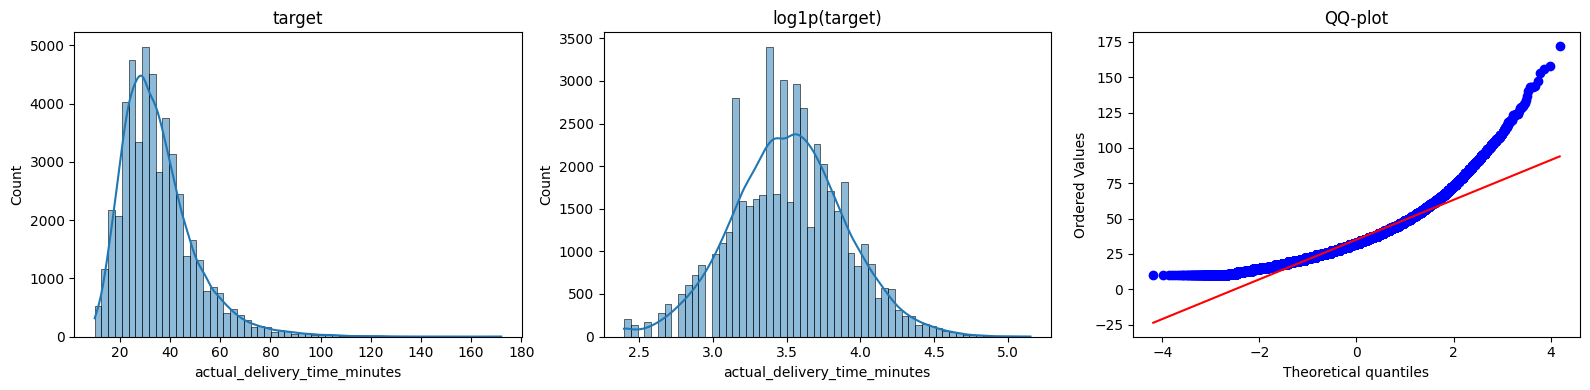

In [13]:
y = df[TARGET]
print(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(y, bins=60, kde=True, ax=ax[0]); ax[0].set_title("target")
sns.histplot(np.log1p(y), bins=60, kde=True, ax=ax[1]); ax[1].set_title("log1p(target)")
stats.probplot(y, dist="norm", plot=ax[2]); ax[2].set_title("QQ-plot")
plt.tight_layout(); plt.show()

Остальные

In [17]:
num_cols = [c for c in CORE_NUM_FEATURES + OTHER if pd.api.types.is_numeric_dtype(df[c])]
cat_cols = [c for c in CORE_CAT_FEATURES + OTHER if c not in num_cols]

def iqr_report(frame, cols):
    rows = []
    for c in cols:
        q1, q3 = frame[c].quantile([.25, .75])
        lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        n_out = ((frame[c] < lo) | (frame[c] > hi)).sum()
        rows.append((c, frame[c].min(), frame[c].median(), frame[c].max(), n_out, round(n_out / len(frame) * 100, 2)))
    return pd.DataFrame(rows, columns=["feature", "min", "median", "max", "outliers (IQR)", "%"])

iqr_report(df, num_cols + [TARGET])

,feature,min,median,max,outliers (IQR),%
0,distance_km,0.8,4.1,20.00,2135,4.35
1,restaurant_preparation_time_minutes,5.0,14.0,73.00,1429,2.91
2,delivery_partner_experience_months,1.0,29.0,60.00,0,0.00
3,delivery_partner_rating,3.2,4.5,5.00,210,0.43
4,order_hour,0.0,14.0,23.00,0,0.00
5,is_weekend,0.0,0.0,1.00,0,0.00
6,customer_age,18.0,27.0,55.00,13,0.03
7,restaurant_rating,2.8,4.2,5.00,84,0.17
8,items_count,1.0,2.0,10.00,967,1.97
9,subtotal,5.1,22.8,362.98,2606,5.30


## Числовые

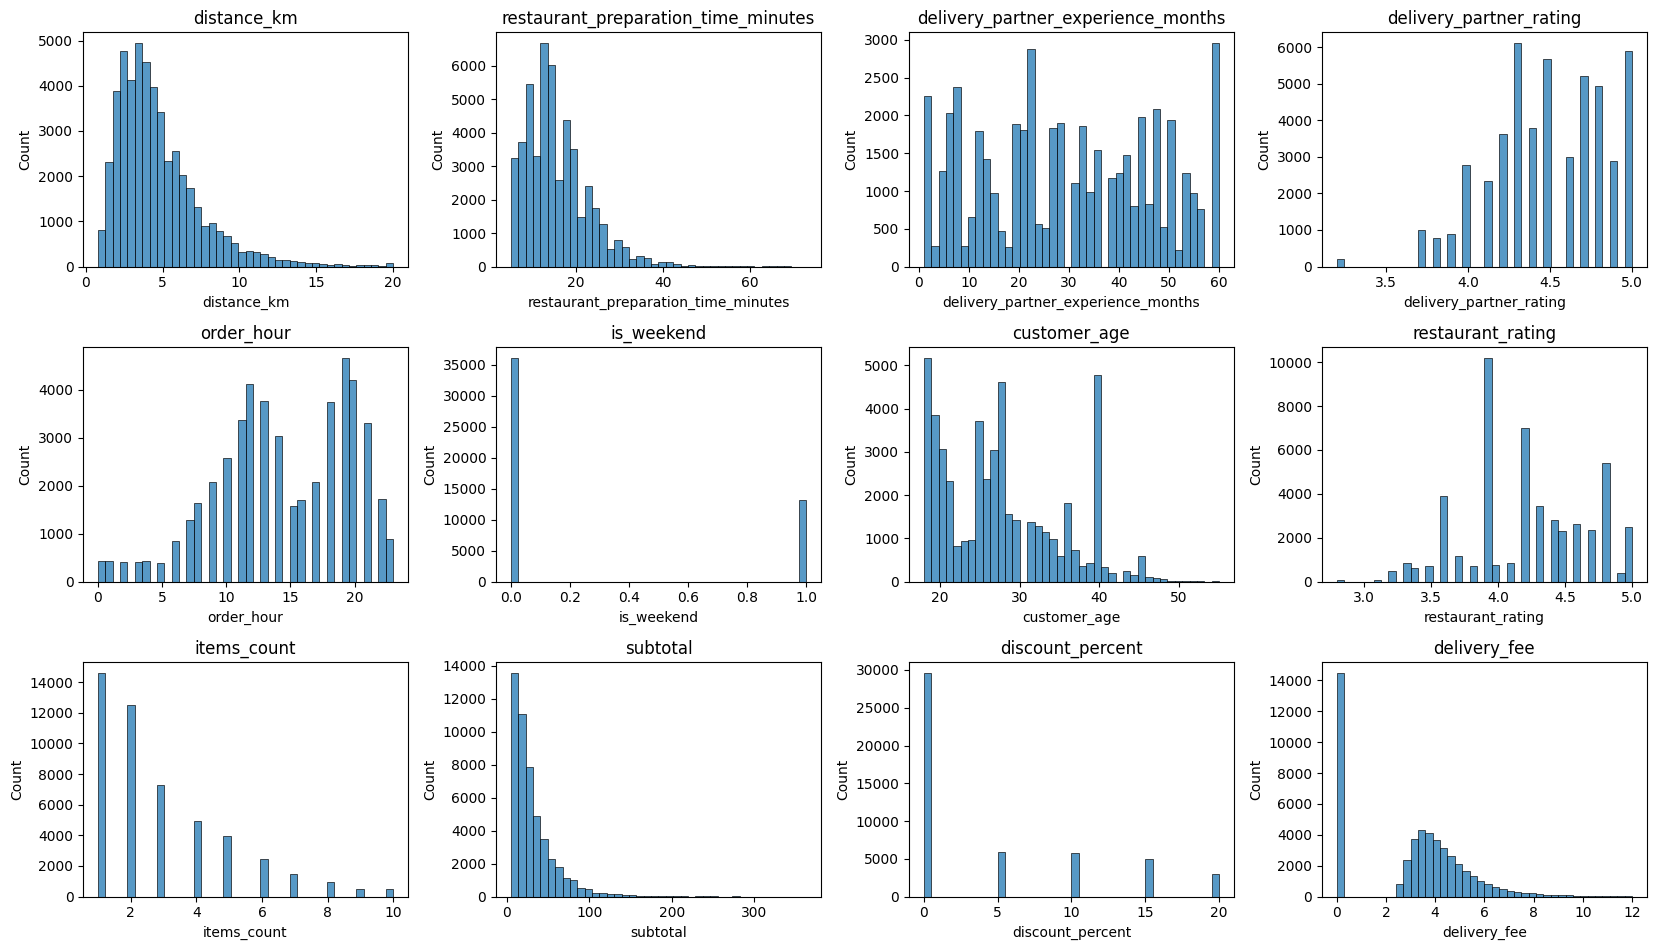

In [18]:
def grid(n, ncols=4, h=3.2):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, h * nrows), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    return fig, axes.ravel()

fig, axes = grid(len(num_cols))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], bins=40, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

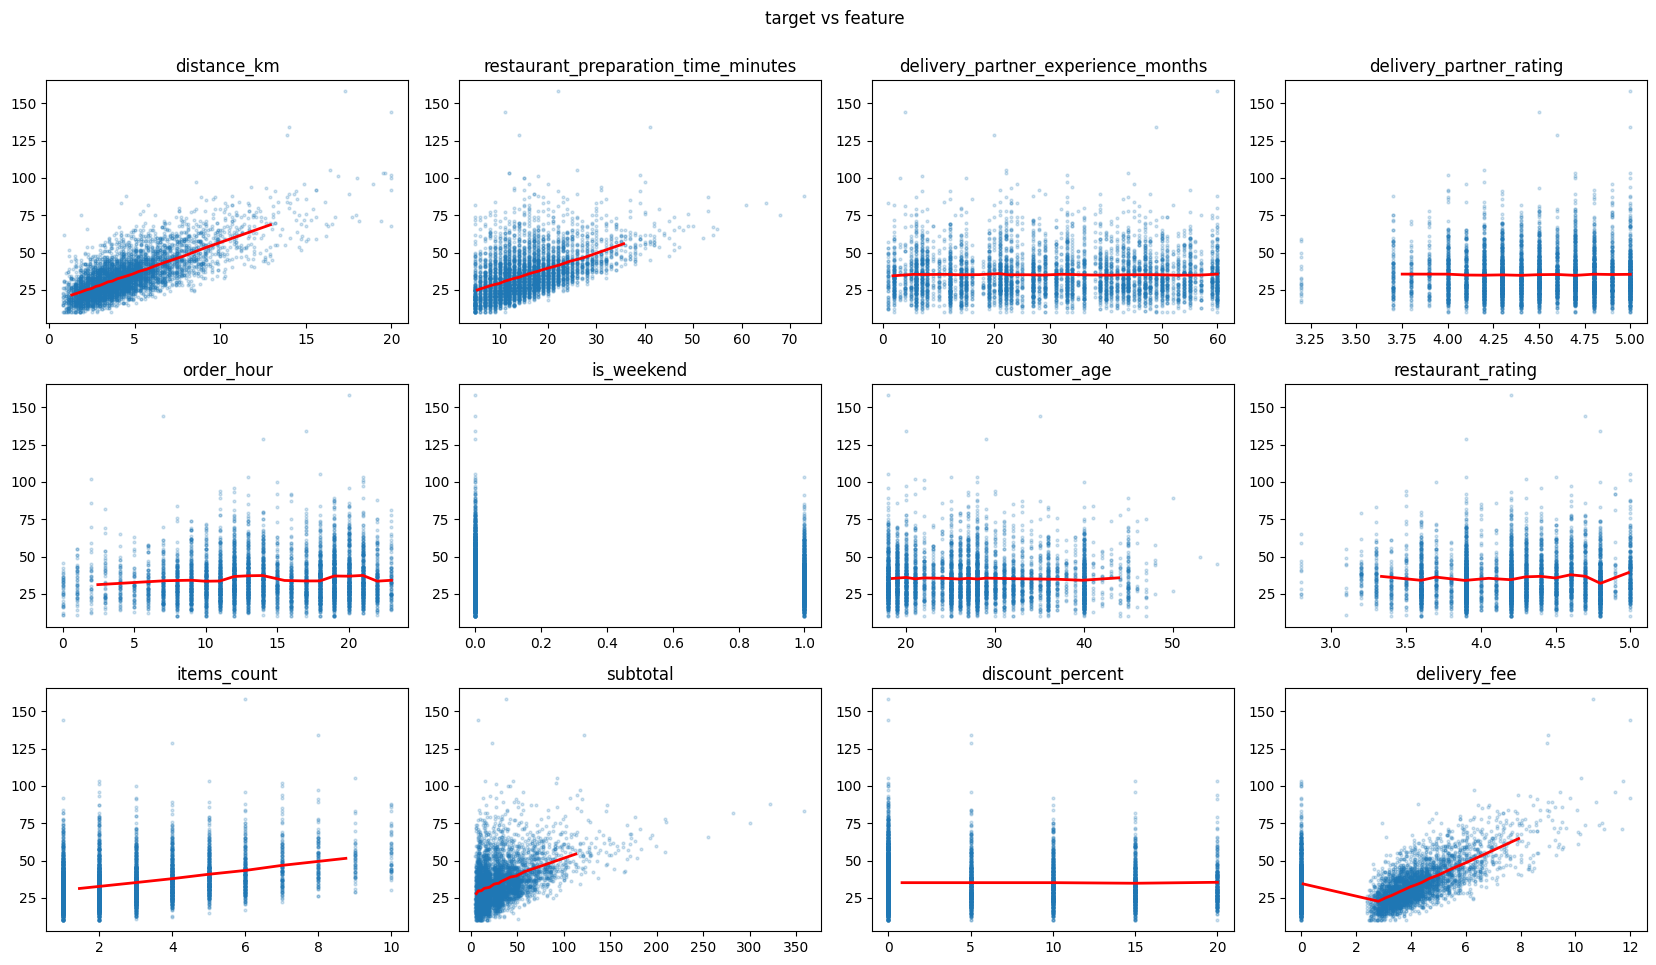

In [20]:
fig, axes = grid(len(num_cols))
for ax, c in zip(axes, num_cols):
    sample = df[[c, TARGET]].sample(5000, random_state=SEED)
    ax.scatter(sample[c], sample[TARGET], s=4, alpha=.2)
    bins = pd.qcut(df[c], 20, duplicates="drop")
    trend = df.groupby(bins, observed=True).agg(x=(c, "mean"), m=(TARGET, "mean"))
    ax.plot(trend["x"], trend["m"], color="red", lw=2)
    ax.set_title(f"{c}")
fig.suptitle("target vs feature", y=1.0)
plt.tight_layout(); plt.show()

**Вывод:** имеется большая корреляция между таргетом и признаками `distance_km`, `restaurant_preparation_time_minutes`. Также коррелируют `subtotal` и `delivery_fee`, но кажется, что эти величины как раз зависят от длительности, посмотрим потом как они повлияют.

## Категориальные


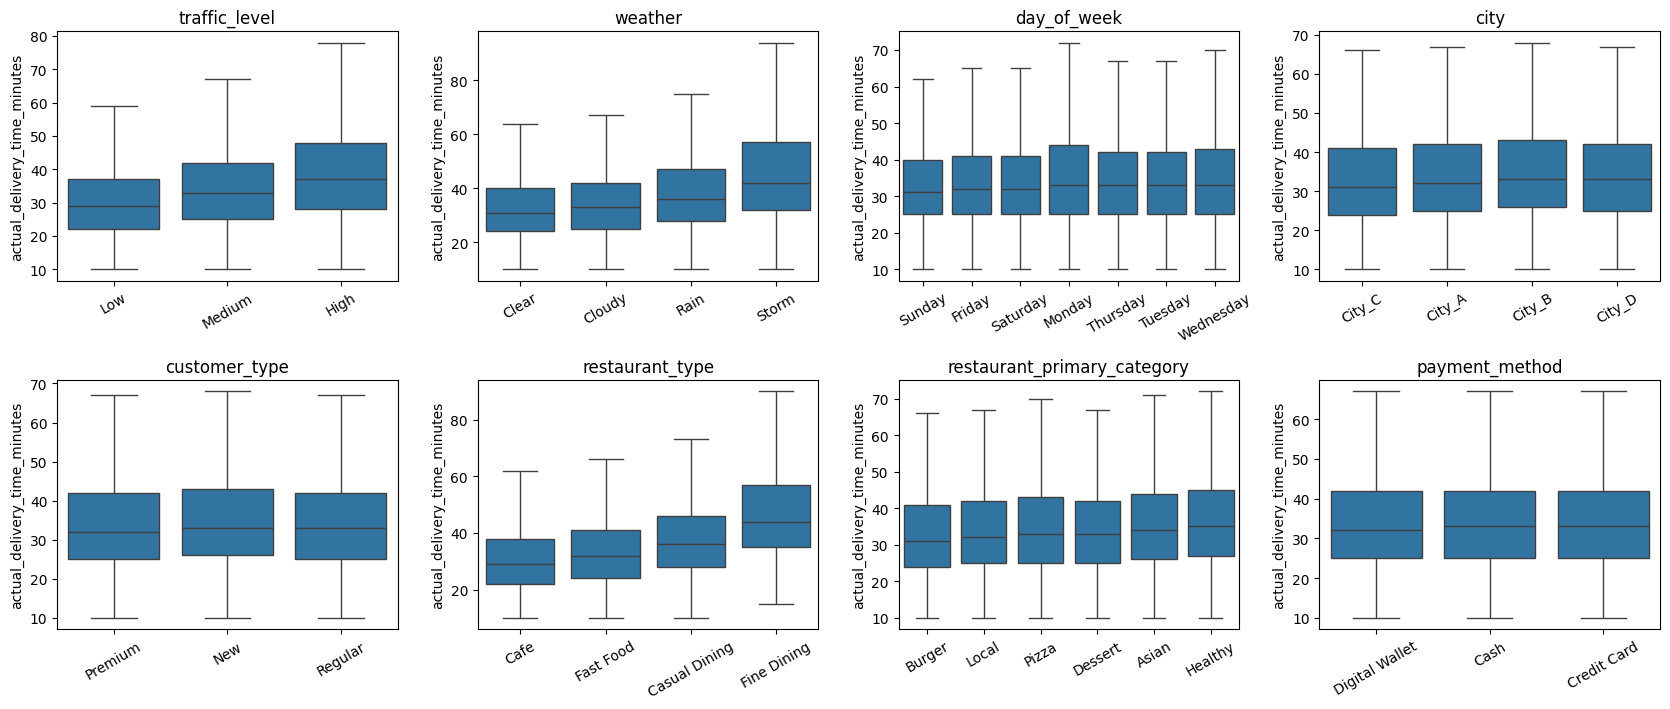

In [21]:
plot_cats = [c for c in cat_cols if df[c].nunique() <= 8]
fig, axes = grid(len(plot_cats), ncols=4, h=3.6)
for ax, c in zip(axes, plot_cats):
    order = df.groupby(c)[TARGET].median().sort_values().index
    sns.boxplot(data=df, x=c, y=TARGET, order=order, ax=ax, showfliers=False)
    ax.set_title(c); ax.tick_params(axis="x", rotation=30); ax.set_xlabel("")
plt.tight_layout(); plt.show()

In [23]:
def eta_squared(groups): # эту штуку использовать подсказал чат гпт
    allv = np.concatenate(groups); grand = allv.mean()
    ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    return ss_b / ((allv - grand) ** 2).sum()

rows = []
for c in cat_cols:
    groups = [g[TARGET].values for _, g in df.groupby(c) if len(g) > 5]
    H, p = stats.kruskal(*groups)
    rows.append((c, df[c].nunique(), round(H, 1), p, round(eta_squared(groups), 4)))
cat_effects = pd.DataFrame(rows, columns=["feature", "amount of categories", "Kruskal H", "p-value", "eta^2"]).sort_values("eta^2", ascending=False)
cat_effects

,feature,amount of categories,Kruskal H,p-value,eta^2
0,traffic_level,3,2997.7,0.000000e+00,0.0609
6,restaurant_type,4,2450.5,0.000000e+00,0.0460
1,weather,4,1328.0,1.252036e-287,0.0349
7,restaurant_primary_category,6,247.7,1.683028e-51,0.0047
2,day_of_week,7,106.6,1.028543e-20,0.0033
4,delivery_area,40,165.7,1.459803e-17,0.0029
3,city,4,131.9,2.075396e-28,0.0022
5,customer_type,3,39.7,2.348298e-09,0.0006
8,payment_method,3,0.8,6.723218e-01,0.0000


**Выводы:** сильнее всего на ответ влияют трафик, тип ресторана и погода. Метод оплаты на ответ не влияет вообще.

## Корреляции

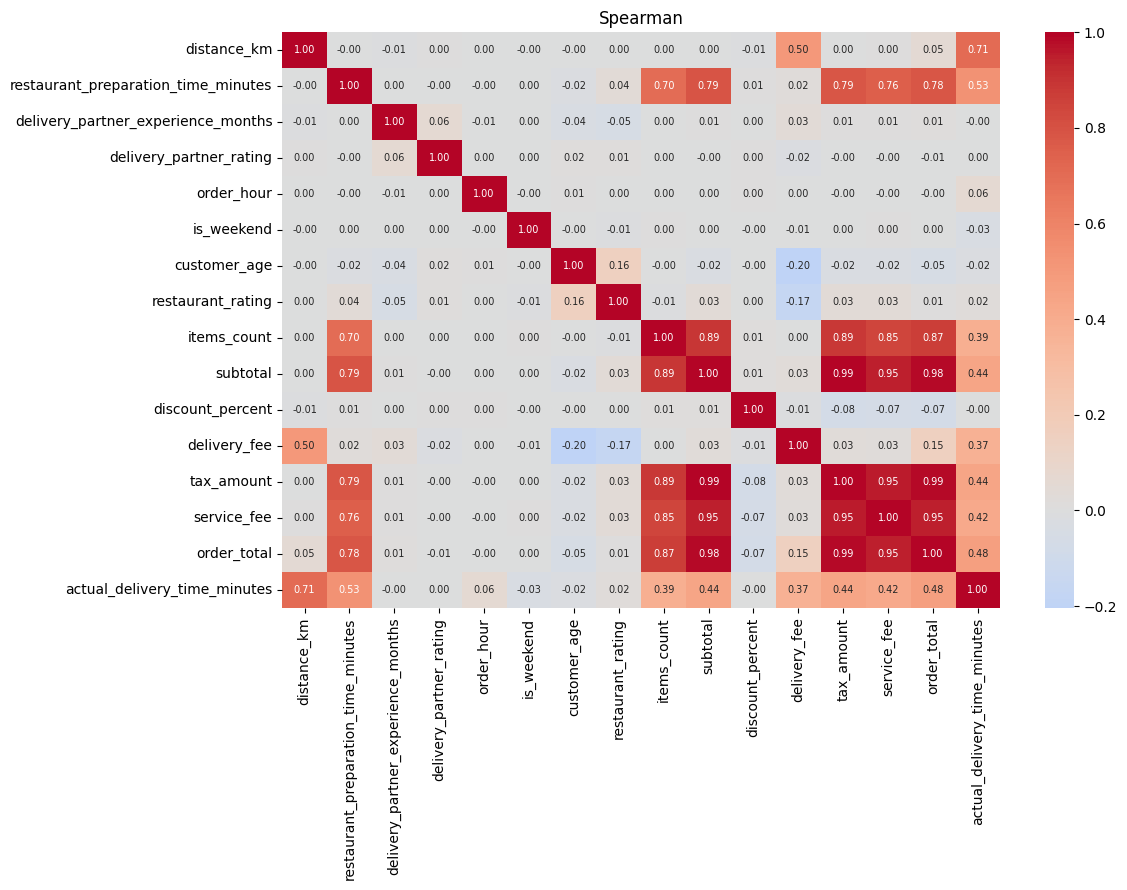

In [24]:
corr_cols = num_cols + ["tax_amount", "service_fee", "order_total", TARGET]
plt.figure(figsize=(12, 9))
sns.heatmap(df[corr_cols].corr("spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.title("Spearman"); plt.tight_layout(); plt.show()

Видно, что признаки курьера не особо коррелируют с таргетом. Также видно, почему убрали `tax_amount`, `service_fee` и `order_total`.

## Бейзлайн - ETA из данных

In [26]:
est = df[BENCHMARK]
err = y - est
bench = pd.Series({
    "MAE": err.abs().mean(),
    "RMSE": np.sqrt((err ** 2).mean()),
    "смещение (факт − ETA)": err.mean(),
    "доля |ошибка| ≤ 5 мин": (err.abs() <= 5).mean(),
    "corr(ETA, факт)": est.corr(y),
}).round(3)
print(bench.to_string())

MAE                      5.244
RMSE                     6.931
смещение (факт − ETA)    4.233
доля |ошибка| ≤ 5 мин    0.616
corr(ETA, факт)          0.930


# Валидация (а точнее проверка, что сплиты корректны)

In [30]:
#эту часть предложил ИИ
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

def build_pipe(num, cat, kind="hgb"):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if kind == "ridge":
        steps.append(("sc", StandardScaler()))
    pre = ColumnTransformer([
        ("num", Pipeline(steps), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
    ])
    model = HistGradientBoostingRegressor(random_state=SEED) if kind == "hgb" else Ridge(alpha=1.0)
    return Pipeline([("pre", pre), ("model", model)])

core_pipe = build_pipe(CORE_NUM_FEATURES, CORE_CAT_FEATURES)
X_core = df[CORE_NUM_FEATURES + CORE_CAT_FEATURES]

def cv_report(name, cv, groups=None):
    s = -cross_val_score(core_pipe, X_core, y, cv=cv, groups=groups, scoring="neg_mean_absolute_error")
    return (name, round(s.mean(), 3), round(s.std(), 3))

rows = [
    cv_report("KFold(5, shuffle)", KFold(5, shuffle=True, random_state=SEED)),
    cv_report("GroupKFold по driver_id", GroupKFold(5), df["driver_id"]),
    cv_report("GroupKFold по restaurant_id", GroupKFold(5), df["restaurant_id"]),
]

cut = pd.Timestamp("2025-10-25")
ts = pd.to_datetime(df["order_timestamp"])
tr, va = (ts < cut).values, (ts >= cut).values
core_pipe.fit(X_core[tr], y[tr])
mae_time = np.abs(core_pipe.predict(X_core[va]) - y[va]).mean()
rows.append(("Временной сплит (1–24 окт → 25–30 окт)", round(mae_time, 3), np.nan))
pd.DataFrame(rows, columns=["схема", "MAE", "std по фолдам"])

,схема,MAE,std по фолдам
0,"KFold(5, shuffle)",2.081,0.020
1,GroupKFold по driver_id,2.084,0.013
2,GroupKFold по restaurant_id,2.081,0.011
3,Временной сплит (1–24 окт → 25–30 окт),2.090,NaN
